# Complex Numbers

A **complex number** has the form $z = a + bi$ where $a, b \in \mathbb{R}$ and $i^2 = -1$.

| Notation | Meaning |
|----------|---------|
| $\text{Re}(z) = a$ | real part |
| $\text{Im}(z) = b$ | imaginary part |
| $|z| = \sqrt{a^2 + b^2}$ | **modulus** (magnitude, distance from origin) |
| $\arg(z) = \arctan\!\frac{b}{a}$ | **argument** (angle with positive real axis) |

**Polar form:** $z = |z|\,(\cos\varphi + i\sin\varphi) = |z|\,e^{i\varphi}$ &ensp; (Euler's formula).


## The Cartesian Plane

The **Cartesian plane** $\mathbb{R}^2$ locates every point by an ordered pair $(x, y)$.
In the **complex plane** (Argand diagram) the horizontal axis becomes the **real axis** and the vertical axis the **imaginary axis**, so the point $(a, b)$ represents $z = a + bi$.


In [ ]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt, ipywidgets as widgets
from IPython.display import display

def plot_cartesian(x, y):
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.set(xlim=(-6, 6), ylim=(-6, 6), aspect='equal', xlabel='x', ylabel='y')
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
    ax.grid(True, alpha=0.3)
    ax.plot(x, y, 'ro', ms=8)
    ax.annotate(f'({x:.1f}, {y:.1f})', (x, y), textcoords='offset points',
                xytext=(10, 10), fontsize=11)
    ax.plot([0, x], [0, y], 'gray', lw=1)
    ax.plot([x, x], [0, y], 'b--', lw=1, label='y-component')
    ax.plot([0, x], [0, 0], 'g--', lw=1, label='x-component')
    ax.legend(fontsize=8)
    ax.set_title('Cartesian Plane')
    plt.tight_layout(); plt.show()

wx = widgets.FloatSlider(value=3, min=-5, max=5, step=0.1, description='x')
wy = widgets.FloatSlider(value=2, min=-5, max=5, step=0.1, description='y')
display(widgets.VBox([wx, wy]),
        widgets.interactive_output(plot_cartesian, {'x': wx, 'y': wy}))


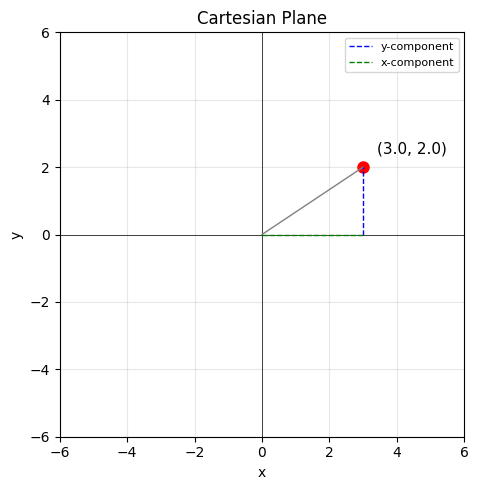

In [ ]:
# Hero figure — the one static image this notebook shows on GitHub.
plot_cartesian(x=wx.value, y=wy.value)

## The Complex Plane — Modulus and Argument

For $z = a + bi$:

$$|z| = \sqrt{a^2 + b^2}, \qquad \varphi = \text{atan2}(b, a)$$

The **modulus** is the distance from the origin; the **argument** is the angle with the positive real axis.

Multiplying two complex numbers **multiplies their moduli** and **adds their arguments**:
$z_1 z_2 = |z_1||z_2|\,e^{i(\varphi_1+\varphi_2)}$.


In [ ]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt, ipywidgets as widgets
from IPython.display import display
from matplotlib.patches import Arc

def plot_complex(a, b):
    z = complex(a, b)
    mod = abs(z)
    phase = np.angle(z)
    t = np.linspace(0, 2 * np.pi, 300)

    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.set(xlim=(-8, 8), ylim=(-8, 8), aspect='equal',
           xlabel='Re', ylabel='Im')
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
    ax.grid(True, alpha=0.3)

    # Modulus circle
    ax.plot(mod * np.cos(t), mod * np.sin(t), 'k', lw=0.4, alpha=0.3)
    # Components
    ax.plot([0, a], [0, 0], 'b--', lw=1.5, label=f'Re = {a:.2f}')
    ax.plot([a, a], [0, b], 'g--', lw=1.5, label=f'Im = {b:.2f}')
    # Magnitude line
    ax.plot([0, a], [0, b], color='gray', lw=2, label=f'|z| = {mod:.2f}')
    ax.plot(a, b, 'ro', ms=8)
    # Phase arc
    if mod > 0.3:
        arc = Arc((0, 0), 1.5, 1.5,angle=0, theta1=0, theta2=np.degrees(phase), color='steelblue', lw=2)
        ax.add_patch(arc)
    ax.legend(fontsize=8, loc='upper left')
    ax.set_title(f'z = {a:.2f} {"+" if b >= 0 else "−"} {abs(b):.2f}i   |   |z| = {mod:.2f}   φ = {np.degrees(phase):.1f}°')
    plt.tight_layout(); plt.show()

wa = widgets.FloatSlider(value=3, min=-7, max=7, step=0.1, description='a (Re)')
wb = widgets.FloatSlider(value=2, min=-7, max=7, step=0.1, description='b (Im)')
display(widgets.VBox([wa, wb]),
        widgets.interactive_output(plot_complex, {'a': wa, 'b': wb}))


## Complex Arithmetic

| Operation | Formula | Geometric meaning |
|-----------|---------|-------------------|
| $z_1 + z_2$ | $(a_1+a_2) + (b_1+b_2)i$ | parallelogram rule (like vector addition) |
| $z_1 \cdot z_2$ | $|z_1||z_2|\,e^{i(\varphi_1+\varphi_2)}$ | scale moduli, add angles |
| $\bar{z}$ | $a - bi$ | reflection across real axis |


In [ ]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt, ipywidgets as widgets
from IPython.display import display

def plot_complex_ops(a1, b1, a2, b2, op):
    z1, z2 = complex(a1, b1), complex(a2, b2)
    if op == 'add':
        zr = z1 + z2; lbl = f'z₁ + z₂ = {zr.real:.2f}{zr.imag:+.2f}i'
    elif op == 'multiply':
        zr = z1 * z2; lbl = f'z₁ · z₂ = {zr.real:.2f}{zr.imag:+.2f}i'
    else:
        zr = z1 - z2; lbl = f'z₁ − z₂ = {zr.real:.2f}{zr.imag:+.2f}i'

    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    lim = max(abs(z1), abs(z2), abs(zr), 2) * 1.4
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect='equal', xlabel='Re', ylabel='Im')
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
    ax.grid(True, alpha=0.3)

    for z, c, name in [(z1, 'blue', 'z₁'), (z2, 'green', 'z₂'), (zr, 'red', 'result')]:
        ax.annotate('', xy=(z.real, z.imag), xytext=(0, 0),
                    arrowprops=dict(arrowstyle='->', color=c, lw=2))
        ax.plot(z.real, z.imag, 'o', color=c, ms=6)
        ax.annotate(name, (z.real, z.imag), textcoords='offset points',
                    xytext=(8, 8), color=c, fontsize=10)
    if op == 'add':
        ax.plot([z1.real, zr.real], [z1.imag, zr.imag], 'g--', lw=1, alpha=0.5)
        ax.plot([z2.real, zr.real], [z2.imag, zr.imag], 'b--', lw=1, alpha=0.5)
    ax.set_title(lbl)
    plt.tight_layout(); plt.show()

wa1 = widgets.FloatSlider(value=2, min=-5, max=5, step=0.1, description='a₁')
wb1 = widgets.FloatSlider(value=1, min=-5, max=5, step=0.1, description='b₁')
wa2 = widgets.FloatSlider(value=1, min=-5, max=5, step=0.1, description='a₂')
wb2 = widgets.FloatSlider(value=2, min=-5, max=5, step=0.1, description='b₂')
wop = widgets.Dropdown(options=['add', 'subtract', 'multiply'], value='add', description='Operation')
ui = widgets.VBox([widgets.HBox([widgets.VBox([wa1, wb1]), widgets.VBox([wa2, wb2])]), wop])
out = widgets.interactive_output(plot_complex_ops, {'a1': wa1, 'b1': wb1, 'a2': wa2, 'b2': wb2, 'op': wop})
display(ui, out)
